# Практическая работа № 4
## Классическое, статистическое и геометрическое определение вероятности

Решены **все задания 4.1–4.17**, включая задания со звёздочками, из файла
«Практические занятия Листок 4 .pdf» (внутренний заголовок PDF: «Листок № 5»).
Составитель листка: проф. П. Е. Рябов.

Оформление и инструменты выбраны по образцу `Prac1.ipynb`, `Prac2.ipynb`,
`Prac3.ipynb`: теория, аналитические решения, вычисления Python, графики и проверки.
Эти ноутбуки посвящены другим темам; условия вероятностных задач взяты из PDF.

**Запуск:** ячейки сверху вниз. Зависимости: `numpy`, `scipy`, `sympy`,
`matplotlib`. В ноутбуке уже сохранены результаты выполнения.
Все опыты воспроизводимы: для каждой задачи задан отдельный seed.
Графики сохраняются в `output/prac4/`. Во всех графиках показаны накопленные
частоты реальных моделируемых опытов, а не искусственные испытания с заранее
подставленной вероятностью события.

**Замечания к исходнику.** Ответ к 4.13 не согласуется с условием.
Формулы 4.12(b,d) требуют упорядочивания времён ожидания.
В 4.10 необходимо определить способ случайного выбора отрезка.
В 4.7 уточнён смысл слов «не пришлось ждать» и «опоздал».
В 4.15–4.17 выводим и две, и одну цифру после запятой: указание об одной
цифре не согласуется с примерами ответов, в которых оставлены две.

## Теория

Для конечного равновероятного пространства $P(A)=|A|/|\Omega|$.
Число неупорядоченных выборок из $n$ по $k$ равно $\binom nk$.
Без возвращения используется гипергеометрическое распределение,
с возвращением — мультиномиальное.

Для равномерной точки области $\Omega$: $P(A)=\mu(A)/\mu(\Omega)$.
Последовательный выбор на случайном интервале обычно **не** даёт постоянной
совместной плотности: нужно учитывать условное распределение.

Условная вероятность $P(A\mid B)=P(A\cap B)/P(B)$.
Формула полной вероятности: $P(A)=\sum_kP(H_k)P(A\mid H_k)$.
Формула Байеса: $P(H_k\mid A)=P(A\mid H_k)P(H_k)/P(A)$.

При независимых повторах $\widehat p_N=N_A/N\to P(A)$ почти наверное
по закону больших чисел. Типичный масштаб ошибки —
$\sqrt{p(1-p)/N}$; сходимость не обязана быть монотонной.
Для условной частоты знаменателем служит число реализаций условия $N_B$,
а не общее число опытов $N$. Пока $N_B=0$, частота не определена.

In [1]:
from pathlib import Path
from fractions import Fraction
from math import comb, factorial
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import quad

OUT = Path('output/prac4')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
N = 150_000
results = []

def report(task, event, estimate, exact=None, denominator=None):
    row = {'task': task, 'event': event, 'estimate': float(estimate),
           'exact': None if exact is None else float(exact),
           'denominator': denominator}
    results.append(row)
    line = f'{task}, {event}: частота = {estimate:.8f}'
    if exact is not None:
        line += f'; теория = {float(exact):.8f}'
    if denominator is not None:
        line += f'; знаменатель = {denominator}'
    print(line)

def convergence(task, events, exact=None, conditions=None):
    exact = exact or {}
    conditions = conditions or {}
    fig, axes = plt.subplots(1, len(events), figsize=(5*len(events), 3.5), squeeze=False)
    for ax, (name, event) in zip(axes[0], events.items()):
        event = np.asarray(event, dtype=bool)
        condition = np.asarray(conditions.get(name, np.ones(len(event), bool)), dtype=bool)
        denominator = np.cumsum(condition)
        numerator = np.cumsum(event & condition)
        frequency = np.divide(numerator, denominator, out=np.full(len(event), np.nan), where=denominator>0)
        # Все частоты рассчитаны; прореживаем только отрисовку больших массивов.
        idx = np.unique(np.r_[np.arange(min(1000,len(event))), np.linspace(0,len(event)-1,3500).astype(int)])
        ax.plot(idx+1, frequency[idx], lw=0.8, label='Относительная частота')
        if name in exact:
            ax.axhline(float(exact[name]), color='crimson', ls='--', label='Точная вероятность')
        ax.set(xlabel='N — число опытов', ylabel='Частота', title=f'{task}: {name}')
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
        report(task,name,frequency[-1],exact.get(name),int(denominator[-1]))
    fig.tight_layout()
    fig.savefig(OUT / f'{task.replace(".", "_")}.png', dpi=140, bbox_inches='tight')
    plt.show()

## 4.1. Шары без возвращения и с возвращением

Общее число выборок равно $\binom{23}{6}$. Поэтому
$$P(A)=\frac{\binom96}{\binom{23}6}=\frac4{4807}\approx0.000832119825,$$
$$P(B)=\frac{\binom63\binom82\binom91}{\binom{23}6}
=\frac{240}{4807}\approx0.04992718952,$$
$$P(D)=\frac{\binom84\binom{15}2}{\binom{23}6}
=\frac{350}{4807}\approx0.07281048471.$$
Для $D$ оставшиеся два шара имеют любой небелый цвет.

**С возвращением:** шесть извлечений независимы, поэтому
$$P(A)=\left(\frac9{23}\right)^6=\frac{531441}{148035889}
\approx0.00358994703,$$
$$P(B)=\frac{6!}{3!2!1!}\left(\frac6{23}\right)^3
\left(\frac8{23}\right)^2\frac9{23},\qquad
P(D)=\binom64\left(\frac8{23}\right)^4\left(\frac{15}{23}\right)^2.$$
Частота $0.00358549$ из листка близка к точной вероятности $A$, но не
определяет её точно. Для редкого события берём миллион опытов.

4.1 без возвращения, A: частота = 0.00089700; теория = 0.00083212; знаменатель = 1000000
4.1 без возвращения, B: частота = 0.05015600; теория = 0.04992719; знаменатель = 1000000
4.1 без возвращения, D: частота = 0.07289000; теория = 0.07281048; знаменатель = 1000000
С возвращением: A = 531441/148035889 ≈ 0.003589947029669272
С возвращением: B = 7464960/148035889 ≈ 0.050426690787123925
С возвращением: D = 13824000/148035889 ≈ 0.09338276071689616
4.1 с возвращением, A: частота = 0.00357900; теория = 0.00358995; знаменатель = 1000000
4.1 с возвращением, B: частота = 0.05038900; теория = 0.05042669; знаменатель = 1000000
4.1 с возвращением, D: частота = 0.09338400; теория = 0.09338276; знаменатель = 1000000


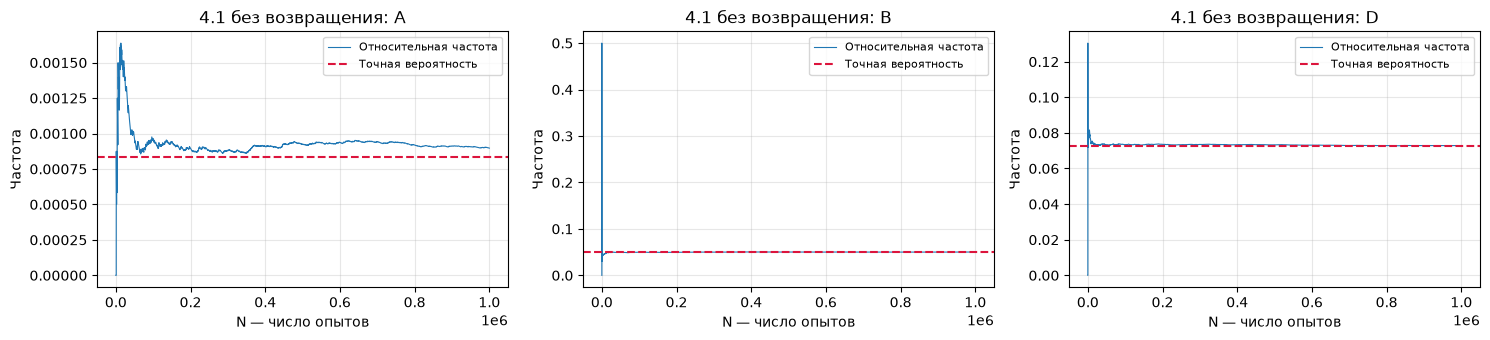

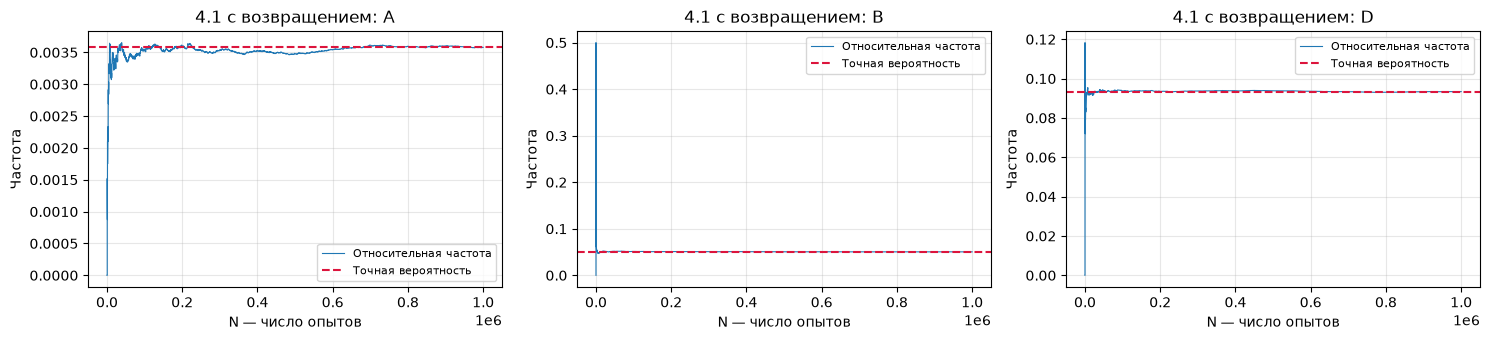

In [2]:
rng = np.random.default_rng(401)
n1 = 1_000_000
# Цвета в порядке: белые, синие, красные. Последовательная гипергеометрия.
white = rng.hypergeometric(8, 15, 6, size=n1)
blue = rng.hypergeometric(6, 9, 6-white)
red = 6-white-blue
exact1 = {'A': Fraction(4,4807), 'B': Fraction(240,4807), 'D': Fraction(350,4807)}
convergence('4.1 без возвращения', {'A': red==6, 'B': (blue==3)&(white==2)&(red==1), 'D': white==4}, exact1)
counts = rng.multinomial(6, [8/23,6/23,9/23],size=n1)
exact1r = {'A': Fraction(9,23)**6,
           'B': 60*Fraction(6,23)**3*Fraction(8,23)**2*Fraction(9,23),
           'D': 15*Fraction(8,23)**4*Fraction(15,23)**2}
for key,value in exact1r.items(): print('С возвращением:',key,'=',value,'≈',float(value))
convergence('4.1 с возвращением', {'A': counts[:,2]==6,
    'B': np.all(counts==[2,3,1],axis=1), 'D': counts[:,0]==4}, exact1r)

## 4.2. Рассадка пяти мужчин и пяти женщин

**A.** Рассадим мужчин: $5!$ способов. В шести промежутках (включая края)
выбираем пять для женщин: $\binom65$, затем переставляем женщин: $5!$.
$$P(A)=\frac{5!\binom655!}{10!}=\frac1{42}.$$
**B.** Считаем мужчин одним блоком. Перестановок блока и пяти женщин $6!$,
внутренних порядков мужчин $5!$:
$$P(B)=\frac{6!5!}{10!}=\frac1{42}.$$

4.2, A: частота = 0.02332000; теория = 0.02380952; знаменатель = 150000
4.2, B: частота = 0.02441333; теория = 0.02380952; знаменатель = 150000


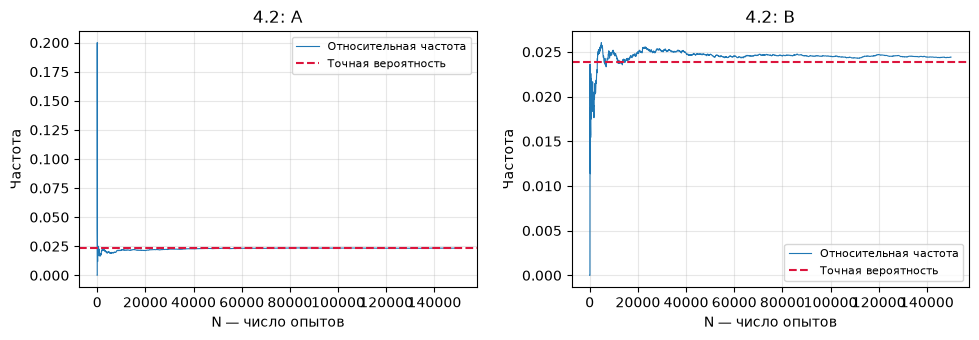

In [3]:
rng = np.random.default_rng(402)
# Случайная перестановка 10 различных людей; номера 0,...,4 — женщины.
people = np.argsort(rng.random((N,10)),axis=1)
women = people < 5
men_positions = np.sort(np.where(~women, np.arange(10), 10),axis=1)[:,:5]
convergence('4.2', {'A': ~np.any(women[:,:-1]&women[:,1:],axis=1),
                     'B': men_positions[:,-1]-men_positions[:,0]==4},
            {'A':Fraction(1,42),'B':Fraction(1,42)})

## 4.3. До первого герба

Пусть $T$ — номер первого герба. $P(T=k)=2^{-k}$, $k\ge1$.
Событие $T>5$ означает пять решек подряд, поэтому
$$\boxed{P(T\le5)=1-2^{-5}=31/32=0.96875.}$$

4.3, T ≤ 5: частота = 0.96846667; теория = 0.96875000; знаменатель = 150000


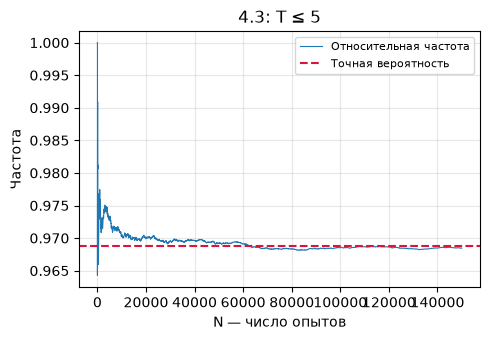

In [4]:
rng = np.random.default_rng(403)
T = rng.geometric(0.5,size=N)
convergence('4.3', {'T ≤ 5': T<=5}, {'T ≤ 5':Fraction(31,32)})

## 4.4. До двух одинаковых результатов подряд: честная монета

Пространство $\Omega$ состоит из конечных слов длины $n\ge2$ над
$\{Г,Р\}$: первые $n-1$ букв чередуются, последняя повторяет предпоследнюю.
Для каждого $n$ таких слов два. Все подмножества измеримы;
вероятность слова длины $n$ равна $2^{-n}$.
Бесконечное чередование имеет вероятность ноль и может быть добавлено
как два нулевых исхода. Нормировка: $\sum_{n=2}^\infty2^{1-n}=1$.

$$P(T=n)=2^{1-n},\qquad
\boxed{P(T\text{ чётно})=\sum_{k=1}^\infty2^{1-2k}=2/3.}$$

4.4, T чётно: частота = 0.66622667; теория = 0.66666667; знаменатель = 150000


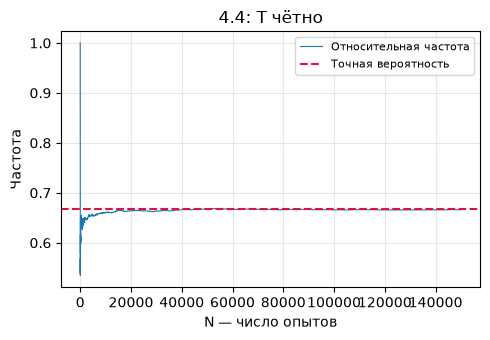

In [5]:
def repeat_stopping_times(rng, p, size):
    last = rng.random(size) < p
    active = np.arange(size)
    times = np.zeros(size,dtype=int)
    step = 1
    while len(active):
        step += 1
        toss = rng.random(len(active)) < p
        stop = toss == last[active]
        times[active[stop]] = step
        last[active] = toss
        active = active[~stop]
    return times

rng = np.random.default_rng(404)
T = repeat_stopping_times(rng,0.5,N)
convergence('4.4', {'T чётно': T%2==0}, {'T чётно':Fraction(2,3)})

## 4.5. Неправильная монета: $p=0.7$, $q=0.3$

Пространство слов то же, но вероятность слова с $h$ гербами и $r$ решками
равна $p^h q^r$. Для $0<p<1$ бесконечное чередование имеет вероятность ноль.
Подсчёт числа гербов и решек в двух словах каждой длины даёт
$$P(T=2k)=(p^2+q^2)(pq)^{k-1},\qquad
P(T=2k+1)=(pq)^k,\quad k\ge1.$$
Обе суммы вместе равны 1. Следовательно,
$$\boxed{P(T\text{ чётно})=\frac{p^2+q^2}{1-pq}=\frac{58}{79}
\approx0.7341772152,}$$
$$\boxed{P(T\text{ кратно }4)
=\frac{(p^2+q^2)pq}{1-(pq)^2}=\frac{1218}{9559}
\approx0.1274191861.}$$


4.5, T чётно: частота = 0.73526667; теория = 0.73417722; знаменатель = 150000
4.5, T кратно 4: частота = 0.12849333; теория = 0.12741919; знаменатель = 150000


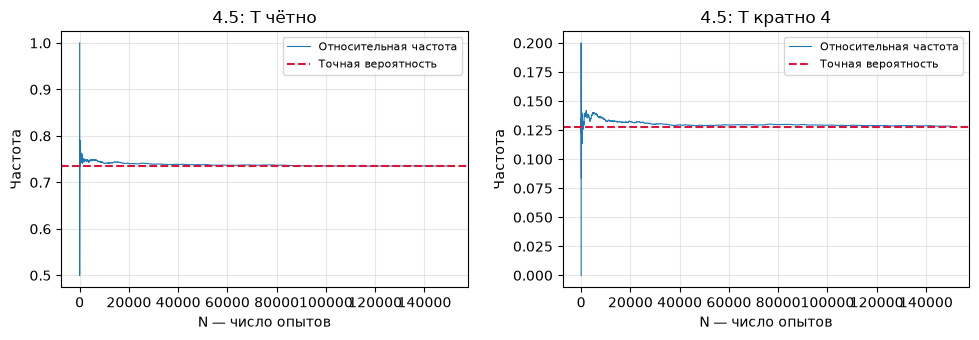

In [6]:
rng = np.random.default_rng(405)
T = repeat_stopping_times(rng,0.7,N)
convergence('4.5', {'T чётно':T%2==0,'T кратно 4':T%4==0},
            {'T чётно':Fraction(58,79),'T кратно 4':Fraction(1218,9559)})

## 4.6. Разные времена ожидания: 10 и 12 минут

Пусть $X,Y$ — независимые равномерные моменты прихода A и B в минутах
после 14:00. Встреча состоится тогда и только тогда, когда
$Y\le X+10$ и $X\le Y+12$. В квадрате $[0,60]^2$ исключаются два треугольника:
$$\boxed{P=1-\frac{50^2+48^2}{2\cdot60^2}=\frac{599}{1800}
\approx0.3327777778.}$$

4.6, Встреча: частота = 0.33220000; теория = 0.33277778; знаменатель = 150000


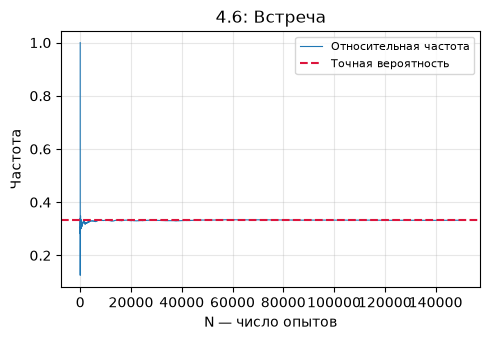

In [7]:
rng = np.random.default_rng(406)
X,Y = rng.uniform(0,60,(2,N))
meet = (Y<=X+10)&(X<=Y+12)
convergence('4.6', {'Встреча':meet}, {'Встреча':Fraction(599,1800)})

## 4.7. Встреча Ивана и Петра

Пусть $X,Y\sim U[0,1]$ — моменты прихода Ивана и Петра после 11:00;
$h=1/4$. Ограничение ожидания концом часа не меняет условие встречи:
$M=\{|X-Y|\le h\}$, момент встречи $Z=\max(X,Y)$.

* **A:** $P(M)=1-(1-h)^2=\boxed{7/16}$.
* **B:** $P(\overline M)=\boxed{9/16}$.
* **C:** «Ивану не пришлось ждать» означает, что он застал Петра:
  $Y\le X\le Y+h$. Это половина полосы встречи: $\boxed{7/32}$.
* **D:** встреча после 11:30. До 11:30 площадь полосы в квадрате
  $[0,1/2]^2$ равна $1/4-(1/2-h)^2=3/16$.
  Значит $P(M,Z>1/2)=7/16-3/16=\boxed{1/4}$.
* **E:** формулировка «опоздал на встречу» неоднозначна. Если Иван пришёл,
  когда Пётр уже ушёл, $X>Y+h$, ответ $\boxed{9/32}$.
  Если имеется в виду только «пришёл позже Петра», $X>Y$, ответ
  $\boxed{1/2}$. Оба варианта смоделированы ниже.
* **F:** встреча в последние пять минут: $Z>11/12$.
  Для $t\ge h$, $P(M,Z\le t)=t^2-(t-h)^2=2ht-h^2$.
  Поэтому $P(M,Z>11/12)=2h(1-11/12)=\boxed{1/24}$.

Если C понимать как «Иван пришёл позже Петра» без требования встречи,
получится $1/2$; это иное событие. Все ответы выше безусловные.

4.7 группа 1, A: частота = 0.43853333; теория = 0.43750000; знаменатель = 150000
4.7 группа 1, B: частота = 0.56146667; теория = 0.56250000; знаменатель = 150000
4.7 группа 1, C: частота = 0.21886000; теория = 0.21875000; знаменатель = 150000
4.7 группа 2, D: частота = 0.25111333; теория = 0.25000000; знаменатель = 150000
4.7 группа 2, E: частота = 0.28128000; теория = 0.28125000; знаменатель = 150000
4.7 группа 2, F: частота = 0.04154000; теория = 0.04166667; знаменатель = 150000
4.7 группа 3, E (позже Петра): частота = 0.50014000; теория = 0.50000000; знаменатель = 150000


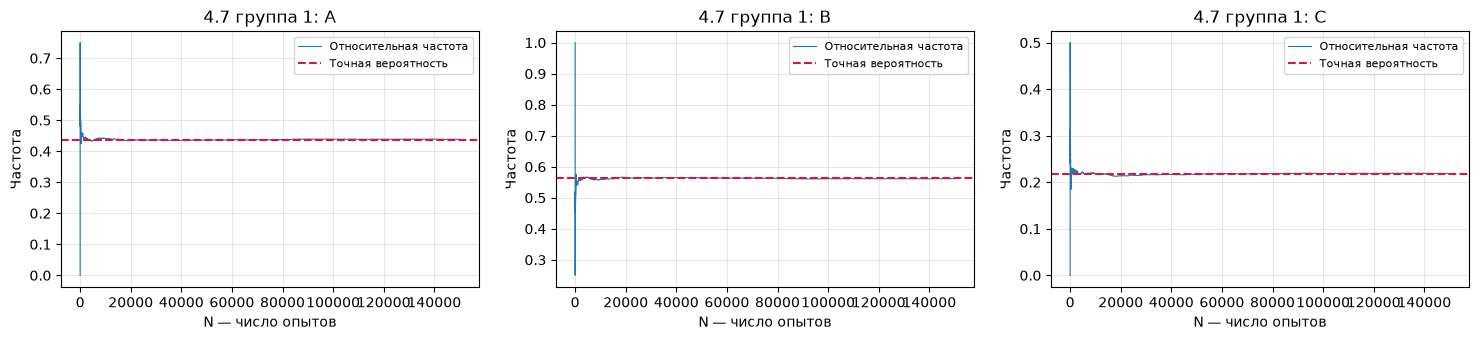

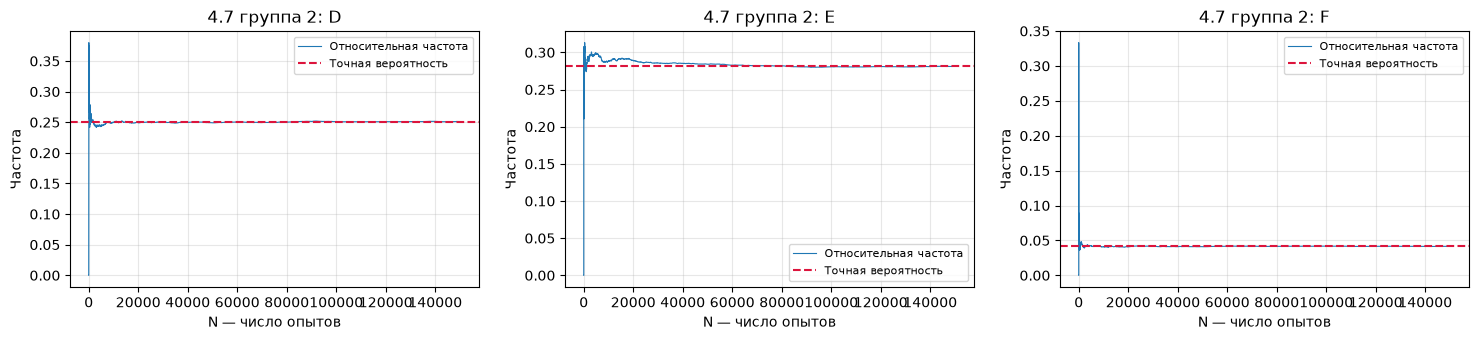

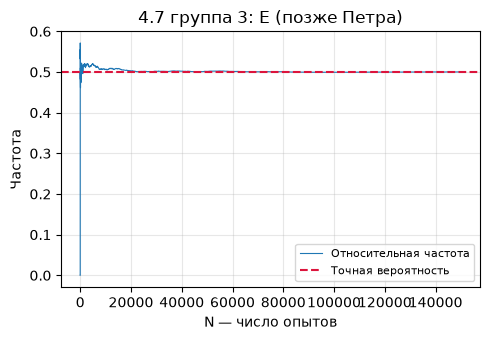

In [8]:
rng = np.random.default_rng(407)
X,Y = rng.random((2,N)); h = 1/4
M = np.abs(X-Y)<=h
events = {'A':M, 'B':~M, 'C':M&(X>=Y),
          'D':M&(np.maximum(X,Y)>0.5), 'E':X>Y+h,
          'F':M&(np.maximum(X,Y)>11/12), 'E (позже Петра)':X>Y}
exact = dict(zip(events,[Fraction(7,16),Fraction(9,16),Fraction(7,32),
                         Fraction(1,4),Fraction(9,32),Fraction(1,24),Fraction(1,2)]))
for j, names in enumerate([['A','B','C'],['D','E','F'],['E (позже Петра)']]):
    convergence(f'4.7 группа {j+1}',{k:events[k] for k in names},{k:exact[k] for k in names})

## 4.8. Последовательный выбор двух точек

При $a<b$ аффинно приводим отрезок к $[0,1]$. Тогда
$X\sim U[0,1]$, $Y\mid X=x\sim U[0,x]$ и
$f_{X,Y}(x,y)=1/x$, $0<y<x<1$. Нельзя считать треугольник исходов
равномерным. В условии пропущено обозначение второй координаты; используем $y$.

**A:** $1-Y<X$, то есть $Y>1-X$:
$$\boxed{P(A)=\int_{1/2}^1\frac{2x-1}{x}\,dx=1-\ln2
\approx0.3068528194.}$$
**B:** $X-Y<1/2$:
$$\boxed{P(B)=\int_0^{1/2}1\,dx+\int_{1/2}^1\frac{1}{2x}\,dx
=\frac{1+\ln2}{2}\approx0.8465735903.}$$
**C:** $X-Y<1-X$, то есть $Y>2X-1$:
$$\boxed{P(C)=\frac12+\int_{1/2}^1\frac{1-x}{x}\,dx=\ln2
\approx0.6931471806.}$$

4.8, A: частота = 0.30724667; теория = 0.30685282; знаменатель = 150000
4.8, B: частота = 0.84640000; теория = 0.84657359; знаменатель = 150000
4.8, C: частота = 0.69348000; теория = 0.69314718; знаменатель = 150000


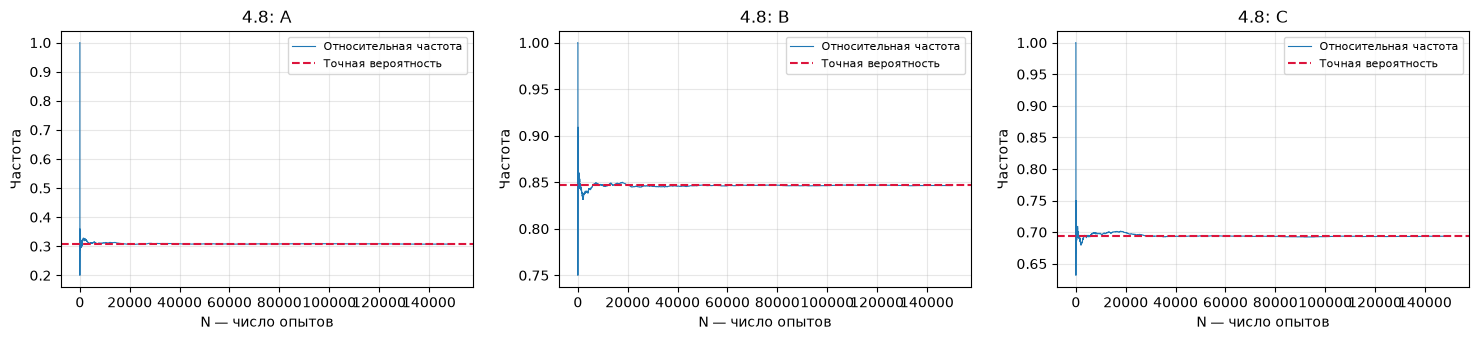

In [9]:
rng = np.random.default_rng(408)
X = rng.random(N); Y = X*rng.random(N)
convergence('4.8', {'A':1-Y<X, 'B':X-Y<0.5, 'C':X-Y<1-X},
            {'A':1-np.log(2),'B':(1+np.log(2))/2,'C':np.log(2)})

## 4.9. Сломанная палочка: остроугольный треугольник

Модель: две независимые равномерные точки разреза на $[0,1]$, затем
их упорядочивание. Длины $(a,b,c)$ равномерны с плотностью 2
на симплексе $a,b,c>0$, $a+b+c=1$. Последовательное разламывание
выбранной части — другая модель и здесь не используется.

Для треугольника $\max(a,b,c)<1/2$. Если самая длинная сторона равна $t$,
то $1/3\le t<1/2$, а вторая сторона $b$ лежит в $[1-2t,t]$.
Остроугольность эквивалентна $t^2<b^2+(1-t-b)^2$.
При $t\le\sqrt2-1$ она выполняется на всём интервале;
при больших $t$ исключается центральный интервал ширины
$\sqrt{t^2+2t-1}$. Учитывая три выбора наибольшей стороны и плотность 2,
$$P=6\left[\int_{1/3}^{1/2}(3t-1)\,dt
-\int_{\sqrt2-1}^{1/2}\sqrt{t^2+2t-1}\,dt\right].$$
Первый интеграл равен $1/24$.
Для второго используем первообразную
$$\frac12(t+1)\sqrt{t^2+2t-1}
-\ln\left(t+1+\sqrt{t^2+2t-1}\right),$$
откуда интеграл равен $3/8-\frac12\ln2$. Поэтому
$$\boxed{P=3\ln2-2\approx0.07944154168.}$$
Это вероятность и существования, и остроугольности, без условливания
на существование треугольника. Условная вероятность равна $4P$,
поскольку вероятность собрать любой треугольник равна $1/4$.

4.9, Остроугольный треугольник: частота = 0.07994000; теория = 0.07944154; знаменатель = 150000


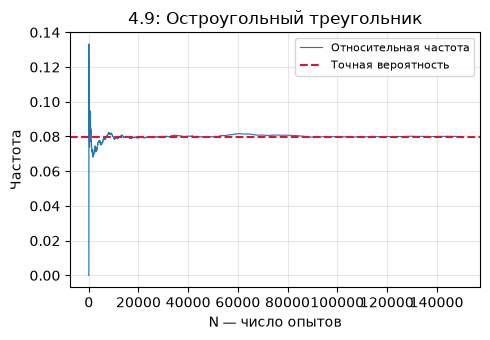

In [10]:
rng = np.random.default_rng(409)
cuts = np.sort(rng.random((N,2)),axis=1)
sides = np.column_stack([cuts[:,0],cuts[:,1]-cuts[:,0],1-cuts[:,1]])
max_side = sides.max(axis=1)
triangle = max_side<0.5
acute = triangle & (2*max_side**2 < np.sum(sides**2,axis=1))
p9 = 3*np.log(2)-2
integral9 = 6*(quad(lambda t:3*t-1,1/3,1/2)[0]-quad(lambda t:np.sqrt(t*t+2*t-1),np.sqrt(2)-1,1/2)[0])
assert np.isclose(integral9,p9,atol=1e-10)
convergence('4.9', {'Остроугольный треугольник':acute}, {'Остроугольный треугольник':p9})

## 4.10. Случайный отрезок в единичном круге

Само выражение «наудачу выбирается отрезок» не задаёт распределения.
Принимаем модель, согласующуюся с ответом листка: **два конца отрезка
независимо и равномерно выбираются по площади круга**.
Это не случайная хорда с концами на окружности.

Площадь пересечения двух единичных кругов с расстоянием $r$ между центрами:
$$I(r)=2\arccos(r/2)-\frac r2\sqrt{4-r^2},\quad0\le r\le2.$$
Плотность вектора разности концов равна $I(r)/\pi^2$.
Интегрируя по кругу векторов длины меньше 1, получаем
$$P=\frac2\pi\int_0^1rI(r)\,dr
=\frac2\pi\left(\frac\pi2-\frac{3\sqrt3}{8}\right)
=\boxed{1-\frac{3\sqrt3}{4\pi}\approx0.5865033284.}$$
Для равномерности по площади радиус генерируется как $\sqrt U$, угол —
как $2\pi V$. Например, при независимых равномерных концах **на окружности**
получился бы другой ответ $1/3$.

4.10, Длина < 1: частота = 0.58594000; теория = 0.58650333; знаменатель = 150000


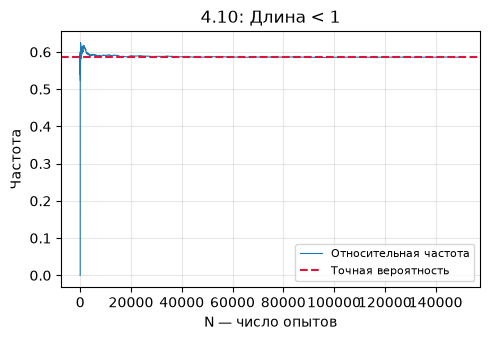

In [11]:
def disk_points(rng, shape):
    r = np.sqrt(rng.random(shape))
    angle = rng.uniform(0,2*np.pi,shape)
    return np.stack([r*np.cos(angle),r*np.sin(angle)],axis=-1)

rng = np.random.default_rng(410)
points = disk_points(rng,(N,2))
event = np.linalg.norm(points[:,0]-points[:,1],axis=1)<1
p10 = 1-3*np.sqrt(3)/(4*np.pi)
intersection = lambda r:2*np.arccos(r/2)-r/2*np.sqrt(4-r*r)
assert np.isclose(2/np.pi*quad(lambda r:r*intersection(r),0,1)[0],p10)
convergence('4.10', {'Длина < 1':event}, {'Длина < 1':p10})

## 4.11. Встреча $n$ лиц с общим временем ожидания $q$

Считаем $0\le q\le1$, независимые времена прихода $X_i\sim U[0,1]$.
Все встретятся тогда и только тогда, когда $\max X_i-\min X_i\le q$.
Почти наверное самый ранний участник единственен. Если он пришёл в $t$,
остальные должны попасть в $[t,\min(1,t+q)]$:
$$P_n=n\int_0^1\min(q,1-t)^{n-1}\,dt
=n(1-q)q^{n-1}+q^n
=\boxed{nq^{n-1}-(n-1)q^n}.$$
Для $n=2$: $P_2=2q-q^2$; для $n=3$: $P_3=3q^2-2q^3$.

Для $n=3$ хотя бы двое встретятся, если хотя бы один соседний промежуток
между упорядоченными временами не больше $q$.
В противоположном случае оба промежутка больше $q$.
Сдвиг $(x_{(1)},x_{(2)},x_{(3)})\mapsto
(x_{(1)},x_{(2)}-q,x_{(3)}-2q)$ оставляет упорядоченный симплекс
длины $1-2q$. Отношение объёмов равно $(1-2q)^3$, если $q\le1/2$.
$$\boxed{P(\text{хотя бы двое})=1-\max(1-2q,0)^3.}$$
Числовое $q$ не задано; для иллюстрации берём $q=1/4$:
$P_2=7/16$, $P_3=5/32$, $P_{\ge2}=7/8$.

4.11, n = 2: частота = 0.43564000; теория = 0.43750000; знаменатель = 150000
4.11, n = 3: частота = 0.15460667; теория = 0.15625000; знаменатель = 150000
4.11, Хотя бы двое: частота = 0.87422000; теория = 0.87500000; знаменатель = 150000


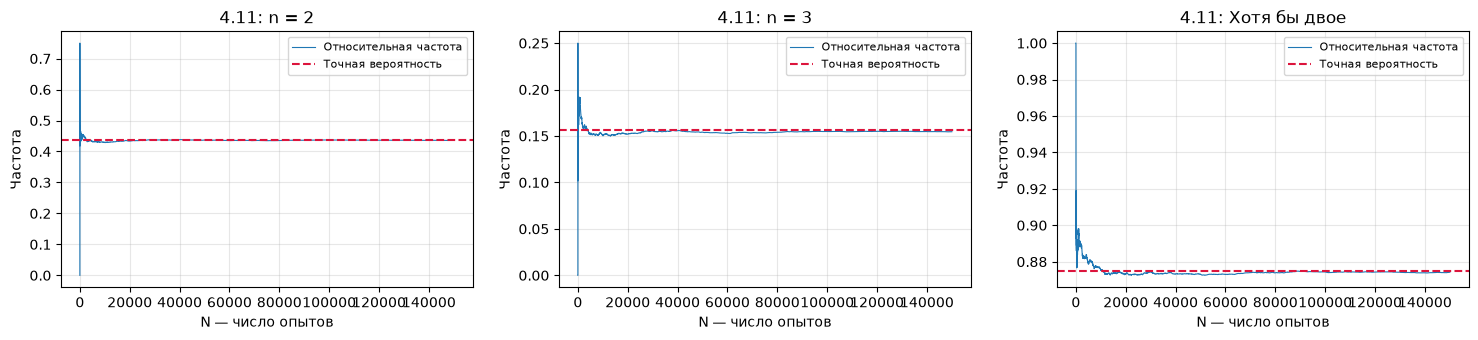

In [12]:
rng = np.random.default_rng(411); q = 0.25
arrivals = rng.random((N,3))
ordered = np.sort(arrivals,axis=1)
convergence('4.11', {'n = 2':np.ptp(arrivals[:,:2],axis=1)<=q,
    'n = 3':np.ptp(arrivals,axis=1)<=q,
    'Хотя бы двое':np.min(np.diff(ordered,axis=1),axis=1)<=q},
    {'n = 2':2*q-q*q,'n = 3':3*q*q-2*q**3,'Хотя бы двое':1-(1-2*q)**3})

## 4.12**. Встреча при разных временах ожидания

Пусть $0\le w_i\le1$. Все участники одновременно присутствуют тогда
и только тогда, когда для последнего момента прихода $t=\max_iX_i$
выполняется $X_i+w_i\ge t$ для всех $i$.
Если последним пришёл участник $j$, каждый другой должен попасть в
$[\max(0,t-w_i),t]$ длины $\min(t,w_i)$. Суммируя по последнему участнику,
получаем общую формулу, верную при любом порядке времён:
$$\boxed{P_n=\sum_{j=1}^n\int_0^1\prod_{i\ne j}\min(t,w_i)\,dt.}$$
Момент последнего прихода единственен почти наверное, поэтому области
не пересекаются, кроме множеств нулевой меры.

**a)** Для двух участников:
$$P_2=\sum_{i=1}^2\left(\int_0^{w_i}t\,dt+\int_{w_i}^1w_i\,dt\right)
=\boxed{1-\frac{(1-w_1)^2}{2}-\frac{(1-w_2)^2}{2}}.$$

Для следующих полиномов **перенумеруем участников так, чтобы**
$w_1\le w_2\le\cdots\le w_n$. В PDF это необходимое условие пропущено.

**b)** При $a\le b$:
$$J_2(a,b)=\int_0^1\min(t,a)\min(t,b)\,dt
=\frac{a^3}{3}+\frac{a(b^2-a^2)}2+ab(1-b)
=ab-\frac{ab^2}{2}-\frac{a^3}{6}.$$
Суммируя $J_2(w_1,w_2)+J_2(w_1,w_3)+J_2(w_2,w_3)$, получаем
$$\boxed{P_3=w_1w_2+w_1w_3+w_2w_3
-\frac12(w_1w_2^2+w_1w_3^2+w_2w_3^2)
-\frac13w_1^3-\frac16w_2^3}.$$

**c)** Для $(w_1,w_2,w_3)=(1/4,1/3,1/2)$:
$$\boxed{P_3=\frac{1435}{5184}\approx0.2768132716}.$$

**d)** Для $a\le b\le c$:
$$J_3(a,b,c)=\frac{a^4}{4}+\frac{a(b^3-a^3)}3
+\frac{ab(c^2-b^2)}2+abc(1-c)
=abc-\frac{abc^2}{2}-\frac{ab^3}{6}-\frac{a^4}{12}.$$
Суммируем $J_3$ по четырём тройкам, исключая каждого участника по очереди:
$$\boxed{\begin{aligned}
P_4={}&w_1w_2w_3+w_1w_2w_4+w_1w_3w_4+w_2w_3w_4\\
&-\frac{w_4^2}{2}(w_1w_2+w_1w_3+w_2w_3)
-\frac{w_3^3}{6}(w_1+w_2)\\
&-\frac{w_1w_2w_3^2}{2}-\frac{w_1w_2^3}{3}
-\frac{w_1^4}{4}-\frac{w_2^4}{12}.
\end{aligned}}$$
Это доказывает формулы листка с добавленным условием сортировки.
При одинаковых $w_i=q$ общая формула даёт результат 4.11.
В числовой иллюстрации d берём $(1/4,1/3,1/2,2/3)$.

4.12(a): точная вероятность = 599/1800
4.12 a, Все встретились: частота = 0.33246000; теория = 0.33277778; знаменатель = 150000
4.12(c): точная вероятность = 1435/5184
4.12 c, Все встретились: частота = 0.27535333; теория = 0.27681327; знаменатель = 150000
4.12(d): точная вероятность = 44957/248832
4.12 d, Все встретились: частота = 0.18126000; теория = 0.18067210; знаменатель = 150000


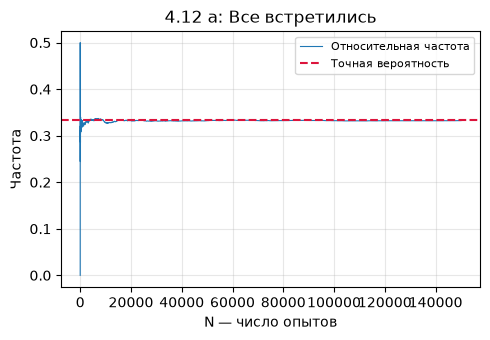

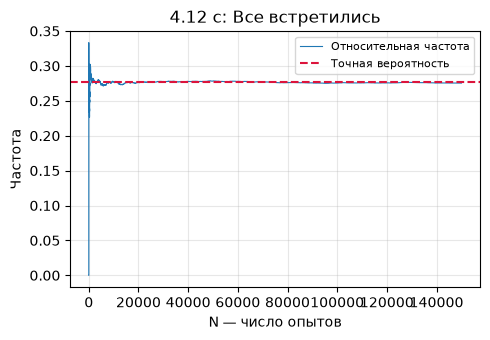

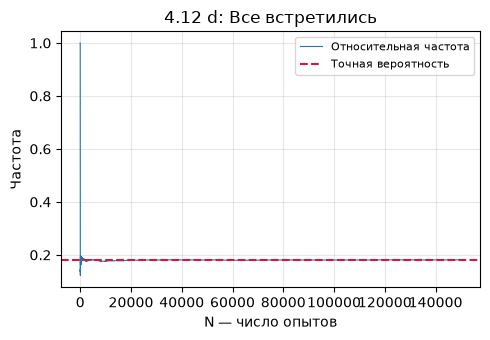

In [13]:
from itertools import combinations

def exact_meeting_probability(waiting):
    # Точное интегрирование полиномов на промежутках между w_i.
    w = [sp.Rational(v) for v in waiting]
    t = sp.Symbol('t',real=True)
    breaks = sorted(set([sp.S(0),sp.S(1)]+w))
    total = sp.S(0)
    for low,high in zip(breaks[:-1],breaks[1:]):
        midpoint = (low+high)/2
        for j in range(len(w)):
            polynomial = sp.prod(t if midpoint<wi else wi for i,wi in enumerate(w) if i!=j)
            total += sp.integrate(polynomial,(t,low,high))
    return sp.simplify(total)

def J2(a,b): return a*b-a*b*b/2-a**3/6
def J3(a,b,c): return a*b*c-a*b*c*c/2-a*b**3/6-a**4/12

w1,w2,w3,w4 = sp.symbols('w1:5',nonnegative=True)
p3poly = sum(J2(*v) for v in combinations([w1,w2,w3],2))
p4poly = sum(J3(*v) for v in combinations([w1,w2,w3,w4],3))
assert sp.simplify(p3poly.subs({w1:q,w2:q,w3:q})-(3*q*q-2*q**3))==0
assert abs(float(p4poly.subs({w1:q,w2:q,w3:q,w4:q}))-(4*q**3-3*q**4))<1e-14
rng = np.random.default_rng(412)
for label,w in [('a',[sp.Rational(1,6),sp.Rational(1,5)]),
                ('c',[sp.Rational(1,4),sp.Rational(1,3),sp.Rational(1,2)]),
                ('d',[sp.Rational(1,4),sp.Rational(1,3),sp.Rational(1,2),sp.Rational(2,3)])]:
    arrivals = rng.random((N,len(w)))
    latest = arrivals.max(axis=1)
    event = np.all(arrivals+np.array(w,dtype=float)>=latest[:,None],axis=1)
    theory = exact_meeting_probability(w)
    print(f'4.12({label}): точная вероятность = {theory}')
    if label=='c': assert theory==sp.Rational(1435,5184)
    if label=='d': assert sp.simplify(p4poly.subs(dict(zip([w1,w2,w3,w4],w)))-theory)==0
    convergence(f'4.12 {label}',{'Все встретились':event},{'Все встретились':theory})

## 4.13. Добавление белого шара

Число белых шаров до добавления $K\sim\operatorname{Bin}(n,p)$.
При $K=k$ после добавления имеется $k+1$ белых шаров из $n+1$.
По формуле полной вероятности (или линейности ожидания):
$$P=\sum_{k=0}^n\binom nkp^k(1-p)^{n-k}\frac{k+1}{n+1}
=\frac{\mathbb E K+1}{n+1}
=\boxed{\frac{np+1}{n+1}}.$$
При $n=10$, $p=1/3$:
$$\boxed{P=\frac{13}{33}\approx0.3939393939}.$$
**В листке напечатано $0.15625$; это не соответствует данному условию.**
Например, правильная формула даёт $p<P<1$ при $p<1$, тогда как
$0.15625<1/3$. В каждом независимом повторе заново выбирается состав корзины.

4.13, Белый шар: частота = 0.39422667; теория = 0.39393939; знаменатель = 150000


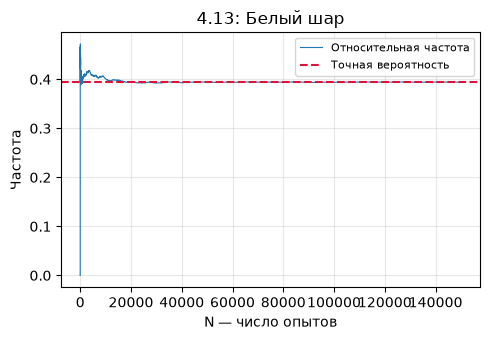

In [14]:
rng = np.random.default_rng(413)
n = 10; p = 1/3
K = rng.binomial(n,p,N)
draw = rng.integers(0,n+1,N)
event = draw<K+1
p13 = sum(Fraction(comb(10,k))*Fraction(1,3)**k*Fraction(2,3)**(10-k)*Fraction(k+1,11) for k in range(11))
assert p13==Fraction(13,33)
convergence('4.13',{'Белый шар':event},{'Белый шар':p13})

## 4.14. Объединение корзин и формула Байеса

В первой корзине 6 шаров, из них $K_1\sim\operatorname{Bin}(3,0.8)$ белых;
во второй 11 шаров, из них $K_2\sim\operatorname{Bin}(4,0.7)$ белых.
Числа 3 и 4 — параметры распределения числа белых шаров, а не размеры корзин.
$$\boxed{P(A)=\frac{\mathbb E K_1+\mathbb E K_2}{17}
=\frac{3\cdot0.8+4\cdot0.7}{17}=\frac{26}{85}
\approx0.3058823529.}$$
Пусть H — происхождение извлечённого шара из первой корзины.
$P(H\cap A)=\mathbb EK_1/17=12/85$, поэтому
$$\boxed{P(H\mid A)=\frac{12/85}{26/85}=\frac6{13}
\approx0.4615384615.}$$

4.14, A: частота = 0.30438667; теория = 0.30588235; знаменатель = 150000
4.14, H | A: частота = 0.45790442; теория = 0.46153846; знаменатель = 45658


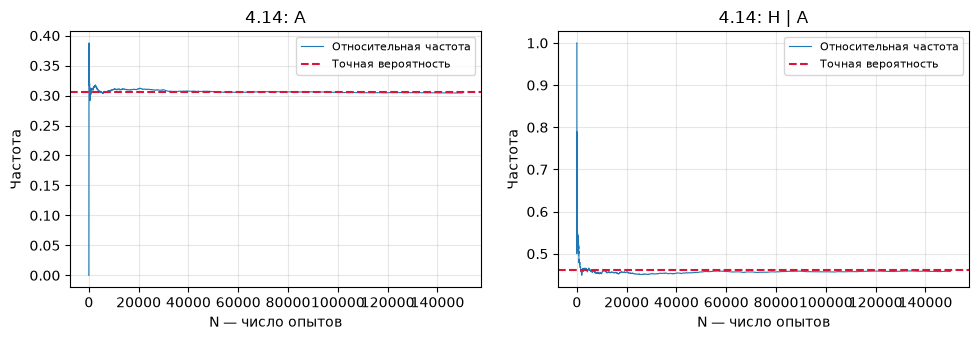

In [15]:
rng = np.random.default_rng(414)
K1 = rng.binomial(3,0.8,N); K2 = rng.binomial(4,0.7,N)
draw = rng.integers(0,17,N)
H = draw<6
A = (H&(draw<K1)) | (~H&((draw-6)<K2))
convergence('4.14',{'A':A,'H | A':H},{'A':Fraction(26,85),'H | A':Fraction(6,13)},
            conditions={'H | A':A})

## 4.15. Две точки в прямоугольнике

Равномерно и независимо генерируем 100 000 пар точек в
$[-20,20]\times[-8,8]$. Для каждой пары:
$$A=\{(x_1-x_2)^2+(y_1-y_2)^2<121\},\qquad
B=\{|x_1-x_2|<14\}.$$
Оценки: $\widehat P(A)=N_A/100000$,
$\widehat P(A\mid B)=N_{A\cap B}/N_B$.
Здесь $A\subset B$ из-за $|x_1-x_2|\le\text{расстояние}<11<14$,
поэтому $N_{A\cap B}=N_A$.

Для независимой проверки: $|\Delta x|$, $|\Delta y|$ имеют плотности
$2(40-u)/40^2$, $2(16-v)/16^2$. Следовательно,
$$P(B)=1-(1-14/40)^2=0.5775,$$
$$P(A)=\int_0^{11}\frac{2(40-u)}{40^2}
\left[\frac{2\sqrt{121-u^2}}{16}-\frac{121-u^2}{16^2}\right]du
\approx0.36919947,$$
$$P(A\mid B)=P(A)/P(B)\approx0.63930644.$$
Итоговые оценки и округления напечатаны ниже.

4.15, A: частота = 0.36869000; теория = 0.36919947; знаменатель = 100000
4.15, A | B: частота = 0.63949838; теория = 0.63930644; знаменатель = 57653
P(A): 0.37 (две цифры); 0.4 (одна цифра)
P(A | B): 0.64 (две цифры); 0.6 (одна цифра)


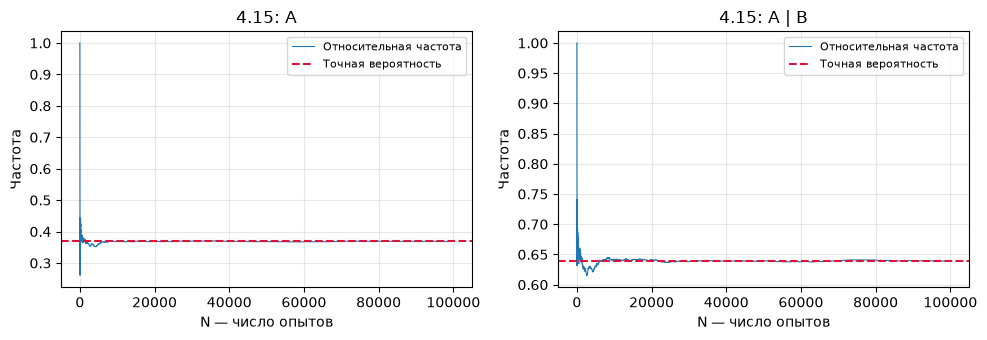

In [16]:
rng = np.random.default_rng(415); n15 = 100_000
points = rng.uniform([-20,-8],[20,8],size=(n15,2,2))
diff = points[:,0]-points[:,1]
A = np.sum(diff**2,axis=1)<121; B = np.abs(diff[:,0])<14
assert np.all(~A|B)
p15 = quad(lambda u:2*(40-u)/40**2*(2*np.sqrt(121-u*u)/16-(121-u*u)/16**2),0,11)[0]
pB15 = 1-(1-14/40)**2
convergence('4.15',{'A':A,'A | B':A},{'A':p15,'A | B':p15/pB15},conditions={'A | B':B})
for label,value in [('P(A)',A.mean()),('P(A | B)',np.count_nonzero(A&B)/B.sum())]:
    print(f'{label}: {value:.2f} (две цифры); {value:.1f} (одна цифра)')

## 4.16. Две точки в эллипсе

Равномерная по площади точка эллипса получается из равномерной точки круга:
$$u=23\sqrt U\cos(2\pi V),\qquad v=6\sqrt U\sin(2\pi V).$$
Линейное преобразование имеет постоянный якобиан $23\cdot6$ и сохраняет
равномерность по площади. Радиус $U$ вместо $\sqrt U$ дал бы ошибочное распределение.

Генерируем 100 000 независимых пар. Проверяем
$A=\{\|P_1-P_2\|<9.2\}$ и
$B=\{u_1>0,v_1>0,u_2<0,v_2<0\}$.
$$\widehat P(A)=\frac{N_A}{100000},\qquad
\widehat P(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
По симметрии $P(B)=1/16$; это помогает проверить выборку.
Ожидаются значения около $0.35$ и $0.07$ (точные числовые оценки ниже).

Для сохранённой выборки условная оценка равна $0.064609$ при $N_B=6253$; её стандартная ошибка около $0.0031$. Поэтому округлённый результат $0.06$ может отличаться от $0.07$ в листке из-за случайной погрешности.


Частота B = 0.062530; теория = 0.062500; N_B = 6253
4.16, A: частота = 0.35118000; знаменатель = 100000
4.16, A | B: частота = 0.06460899; знаменатель = 6253
P(A): 0.35 (две цифры); 0.4 (одна цифра)
P(A | B): 0.06 (две цифры); 0.1 (одна цифра)


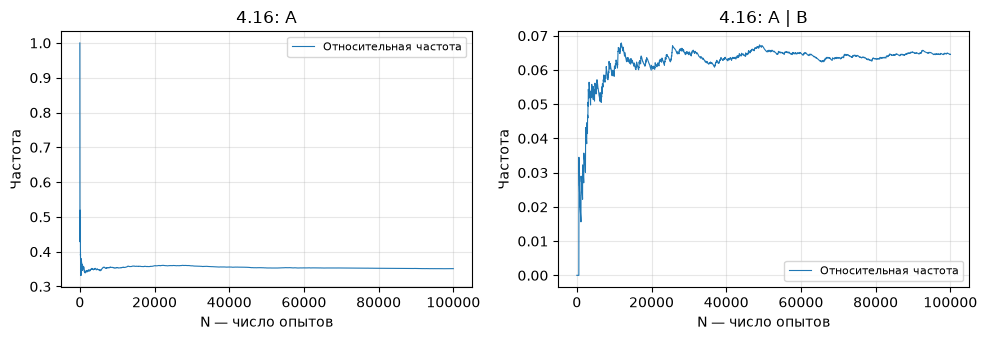

In [17]:
rng = np.random.default_rng(416); n16 = 100_000
points = disk_points(rng,(n16,2))*[23,6]
assert np.all(np.sum((points/[23,6])**2,axis=-1)<=1+1e-14)
A = np.sum((points[:,0]-points[:,1])**2,axis=1)<9.2**2
B = np.all(points[:,0]>0,axis=1)&np.all(points[:,1]<0,axis=1)
print(f'Частота B = {B.mean():.6f}; теория = {1/16:.6f}; N_B = {B.sum()}')
convergence('4.16',{'A':A,'A | B':A},conditions={'A | B':B})
for label,value in [('P(A)',A.mean()),('P(A | B)',np.count_nonzero(A&B)/B.sum())]:
    print(f'{label}: {value:.2f} (две цифры); {value:.1f} (одна цифра)')

## 4.17. Углы случайного остроугольного треугольника в кубе

Без ограничения общности куб — $[0,1]^3$. Генерируем независимые тройки
равномерных точек, отбрасываем неостроугольные и продолжаем,
пока не получим **ровно 100 000 остроугольных треугольников**, как требует листок.
Отбор даёт распределение исходной тройки при условии $T$.

Остроугольность проверяется по положительности скалярных произведений
сторон при каждой вершине. Для углов используем устойчивую формулу
$$\alpha=\operatorname{atan2}(\|\mathbf u\times\mathbf v\|,
\mathbf u\cdot\mathbf v).$$
В каждом принятом треугольнике фиксируем
$R=\{\min\alpha_i<26.7^\circ\}$,
$S=\{\max\alpha_i<81.9^\circ\}$.
$$\widehat P(R\mid T)=\frac{N_R}{100000},\qquad
\widehat P(S\mid T)=\frac{N_S}{100000}.$$
На графиках $N$ — число **принятых остроугольных** треугольников.
Вырожденные тройки имеют вероятность ноль.

Получено 100000 остроугольных треугольников; сгенерировано 250000 троек.
Оценка P(T) по всем сгенерированным тройкам: 0.458152
4.17, R | T: частота = 0.11443000; знаменатель = 100000
4.17, S | T: частота = 0.65313000; знаменатель = 100000
P(R | T): 0.11 (две цифры); 0.1 (одна цифра)
P(S | T): 0.65 (две цифры); 0.7 (одна цифра)


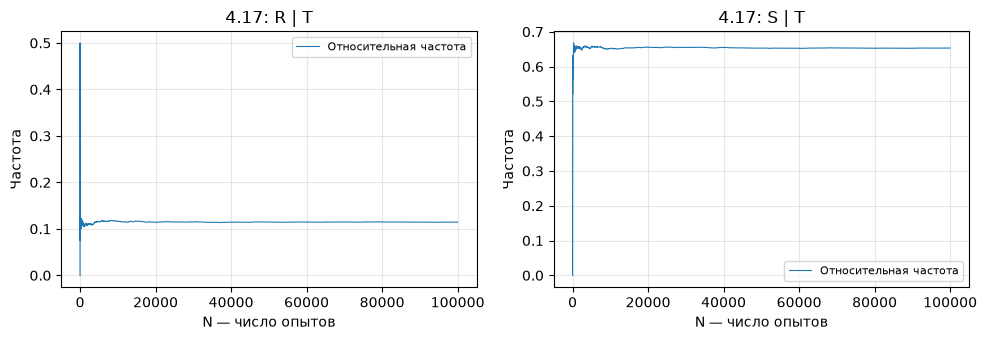

In [18]:
rng = np.random.default_rng(417)
accepted = []; needed = 100_000; attempted = 0; acute_count = 0
while sum(len(batch) for batch in accepted)<needed:
    pts = rng.random((50_000,3,3))
    e01 = pts[:,1]-pts[:,0]; e02 = pts[:,2]-pts[:,0]; e12 = pts[:,2]-pts[:,1]
    dots = np.column_stack([np.sum(e01*e02,axis=1),np.sum(-e01*e12,axis=1),np.sum(e02*e12,axis=1)])
    ok = np.all(dots>0,axis=1)
    accepted.append(pts[ok]); attempted += len(pts); acute_count += int(ok.sum())
pts = np.concatenate(accepted)[:needed]
angles = []
for j in range(3):
    u = pts[:,(j+1)%3]-pts[:,j]; v = pts[:,(j+2)%3]-pts[:,j]
    angles.append(np.degrees(np.arctan2(np.linalg.norm(np.cross(u,v),axis=1),np.sum(u*v,axis=1))))
angles = np.column_stack(angles)
assert len(angles)==100_000 and np.all(angles<90)
assert np.allclose(angles.sum(axis=1),180,atol=1e-8)
R = angles.min(axis=1)<26.7; S = angles.max(axis=1)<81.9
print(f'Получено {len(angles)} остроугольных треугольников; сгенерировано {attempted} троек.')
print(f'Оценка P(T) по всем сгенерированным тройкам: {acute_count/attempted:.6f}')
convergence('4.17',{'R | T':R,'S | T':S})
for label,value in [('P(R | T)',R.mean()),('P(S | T)',S.mean())]:
    print(f'{label}: {value:.2f} (две цифры); {value:.1f} (одна цифра)')

## Сводка вычислений

Таблица содержит сохранённые оценки для всех смоделированных событий.
Прочерк в столбце теории означает, что задача решалась методом Монте-Карло.
Для 4.15 теоретическая проверка получена независимым численным интегрированием.
В условных событиях знаменатель равен числу опытов, удовлетворяющих условию.

In [19]:
import csv
from IPython.display import display, Markdown
lines = ['| Задача | Событие | Оценка | Теория | Знаменатель |',
         '|---|---|---:|---:|---:|']
for row in results:
    theory = '—' if row['exact'] is None else f"{row['exact']:.8f}"
    event = row['event'].replace('|',' / ')
    lines.append(f"| {row['task']} | {event} | {row['estimate']:.8f} | {theory} | {row['denominator']} |")
table = '\n'.join(lines)
display(Markdown(table))
(OUT/'results.md').write_text(table,encoding='utf-8')
with (OUT/'results.csv').open('w',encoding='utf-8-sig',newline='') as f:
    writer = csv.DictWriter(f,fieldnames=['task','event','estimate','exact','denominator'])
    writer.writeheader(); writer.writerows(results)

| Задача | Событие | Оценка | Теория | Знаменатель |
|---|---|---:|---:|---:|
| 4.1 без возвращения | A | 0.00089700 | 0.00083212 | 1000000 |
| 4.1 без возвращения | B | 0.05015600 | 0.04992719 | 1000000 |
| 4.1 без возвращения | D | 0.07289000 | 0.07281048 | 1000000 |
| 4.1 с возвращением | A | 0.00357900 | 0.00358995 | 1000000 |
| 4.1 с возвращением | B | 0.05038900 | 0.05042669 | 1000000 |
| 4.1 с возвращением | D | 0.09338400 | 0.09338276 | 1000000 |
| 4.2 | A | 0.02332000 | 0.02380952 | 150000 |
| 4.2 | B | 0.02441333 | 0.02380952 | 150000 |
| 4.3 | T ≤ 5 | 0.96846667 | 0.96875000 | 150000 |
| 4.4 | T чётно | 0.66622667 | 0.66666667 | 150000 |
| 4.5 | T чётно | 0.73526667 | 0.73417722 | 150000 |
| 4.5 | T кратно 4 | 0.12849333 | 0.12741919 | 150000 |
| 4.6 | Встреча | 0.33220000 | 0.33277778 | 150000 |
| 4.7 группа 1 | A | 0.43853333 | 0.43750000 | 150000 |
| 4.7 группа 1 | B | 0.56146667 | 0.56250000 | 150000 |
| 4.7 группа 1 | C | 0.21886000 | 0.21875000 | 150000 |
| 4.7 группа 2 | D | 0.25111333 | 0.25000000 | 150000 |
| 4.7 группа 2 | E | 0.28128000 | 0.28125000 | 150000 |
| 4.7 группа 2 | F | 0.04154000 | 0.04166667 | 150000 |
| 4.7 группа 3 | E (позже Петра) | 0.50014000 | 0.50000000 | 150000 |
| 4.8 | A | 0.30724667 | 0.30685282 | 150000 |
| 4.8 | B | 0.84640000 | 0.84657359 | 150000 |
| 4.8 | C | 0.69348000 | 0.69314718 | 150000 |
| 4.9 | Остроугольный треугольник | 0.07994000 | 0.07944154 | 150000 |
| 4.10 | Длина < 1 | 0.58594000 | 0.58650333 | 150000 |
| 4.11 | n = 2 | 0.43564000 | 0.43750000 | 150000 |
| 4.11 | n = 3 | 0.15460667 | 0.15625000 | 150000 |
| 4.11 | Хотя бы двое | 0.87422000 | 0.87500000 | 150000 |
| 4.12 a | Все встретились | 0.33246000 | 0.33277778 | 150000 |
| 4.12 c | Все встретились | 0.27535333 | 0.27681327 | 150000 |
| 4.12 d | Все встретились | 0.18126000 | 0.18067210 | 150000 |
| 4.13 | Белый шар | 0.39422667 | 0.39393939 | 150000 |
| 4.14 | A | 0.30438667 | 0.30588235 | 150000 |
| 4.14 | H  /  A | 0.45790442 | 0.46153846 | 45658 |
| 4.15 | A | 0.36869000 | 0.36919947 | 100000 |
| 4.15 | A  /  B | 0.63949838 | 0.63930644 | 57653 |
| 4.16 | A | 0.35118000 | — | 100000 |
| 4.16 | A  /  B | 0.06460899 | — | 6253 |
| 4.17 | R  /  T | 0.11443000 | — | 100000 |
| 4.17 | S  /  T | 0.65313000 | — | 100000 |